# Thiranex Internship — Task 3
## Exploratory Data Analysis (EDA) Project
### Customer Personality & Marketing Campaign Analysis

This notebook follows the EDA workflow demonstrated in Rob Mulla's *Exploratory Data Analysis with Pandas Python 2023*: data loading, data understanding, preparation, feature understanding, feature relationships, and asking questions about the data.

**Objective:** uncover patterns and trends using statistical summaries and visualizations, identify correlations and influencing factors, and present structured insights.


In [1]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Load the dataset

The project uses the Customer Personality Analysis / Marketing Campaign dataset. The public CSV contains customer demographics, purchasing behavior, website/store activity, and campaign response information. The source file is semicolon-separated.


In [2]:
# 2. Load data
DATA_URL = "https://raw.githubusercontent.com/amankharwal/Website-data/master/marketing_campaign.csv"
df = pd.read_csv(DATA_URL, sep=";")

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully.
Shape: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


In [3]:
# 3. Data understanding
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

print("\nDataset information:")
df.info()


Shape: (2240, 29)

Columns:
['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']

Data types:


,dtype
ID,int64
Year_Birth,int64
Education,str
Marital_Status,str
Income,float64
Kidhome,int64
Teenhome,int64
Dt_Customer,str
Recency,int64
MntWines,int64



First 5 rows:


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0



Last 5 rows:


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
2235,10870,1967,Graduation,Married,61223.0,0,1,2013-06-13,46,709,43,182,42,118,247,2,9,3,4,5,0,0,0,0,0,0,3,11,0
2236,4001,1946,PhD,Together,64014.0,2,1,2014-06-10,56,406,0,30,0,0,8,7,8,2,5,7,0,0,0,1,0,0,3,11,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,2014-01-25,91,908,48,217,32,12,24,1,2,3,13,6,0,1,0,0,0,0,3,11,0
2238,8235,1956,Master,Together,69245.0,0,1,2014-01-24,8,428,30,214,80,30,61,2,6,5,10,3,0,0,0,0,0,0,3,11,0
2239,9405,1954,PhD,Married,52869.0,1,1,2012-10-15,40,84,3,61,2,1,21,3,3,1,4,7,0,0,0,0,0,0,3,11,1



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 n

In [4]:
# 4. Statistical summaries
print("Numerical summary:")
display(df.describe().T)

print("\nCategorical summary:")
display(df.describe(include="object").T)


Numerical summary:


,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0



Categorical summary:


C:\Users\thota\AppData\Local\Temp\ipykernel_7128\686679464.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object").T)


,count,unique,top,freq
Education,2240,5,Graduation,1127
Marital_Status,2240,8,Married,864
Dt_Customer,2240,663,2012-08-31,12


In [5]:
# 5. Missing values and duplicates
missing = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().sum() / len(df) * 100).round(2)
})
display(missing[missing["Missing_Count"] > 0].sort_values("Missing_Count", ascending=False))

print("Duplicate rows:", df.duplicated().sum())
print("Unique customer IDs:", df["ID"].nunique())


,Missing_Count,Missing_Percentage
Income,24,1.07


Duplicate rows: 0
Unique customer IDs: 2240


## 3. Data preparation

We keep the raw data unchanged and create a working copy. Missing income values are filled with the median. Dates are converted to datetime, exact duplicates are removed, and useful analysis features are created.


In [6]:
# 6. Clean and prepare data
data = df.copy()

data["Dt_Customer"] = pd.to_datetime(data["Dt_Customer"], errors="coerce")

income_median = data["Income"].median()
data["Income"] = data["Income"].fillna(income_median)

before = len(data)
data = data.drop_duplicates().copy()
print("Duplicate rows removed:", before - len(data))


Duplicate rows removed: 0


In [7]:
# 7. Feature engineering
REFERENCE_YEAR = 2021

data["Age"] = REFERENCE_YEAR - data["Year_Birth"]

product_cols = [
    "MntWines", "MntFruits", "MntMeatProducts",
    "MntFishProducts", "MntSweetProducts", "MntGoldProds"
]

purchase_cols = [
    "NumWebPurchases", "NumCatalogPurchases",
    "NumStorePurchases", "NumDealsPurchases"
]

campaign_cols = [
    "AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3",
    "AcceptedCmp4", "AcceptedCmp5", "Response"
]

data["Total_Spending"] = data[product_cols].sum(axis=1)
data["Total_Purchases"] = data[purchase_cols].sum(axis=1)
data["Total_Campaign_Responses"] = data[campaign_cols].sum(axis=1)
data["Household_Children"] = data["Kidhome"] + data["Teenhome"]

# Remove clearly implausible ages for the main analysis
data = data[(data["Age"] >= 18) & (data["Age"] <= 100)].copy()

print("Prepared shape:", data.shape)
display(data.head())


Prepared shape: (2237, 34)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Total_Spending,Total_Purchases,Total_Campaign_Responses,Household_Children
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1,64,1617,25,1,0
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0,67,27,6,0,2
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0,56,776,21,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0,37,53,8,0,1
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0,40,422,19,0,1


In [8]:
# 8. Verify data quality after preparation
print("Missing values:")
display(data.isna().sum().sort_values(ascending=False).head(10))

print("Duplicates:", data.duplicated().sum())
print("Age range:", data["Age"].min(), "to", data["Age"].max())
print("Median income used for imputation:", income_median)


Missing values:


ID                0
Year_Birth        0
Education         0
Marital_Status    0
Income            0
Kidhome           0
Teenhome          0
Dt_Customer       0
Recency           0
MntWines          0
dtype: int64

Duplicates: 0
Age range: 25 to 81
Median income used for imputation: 51381.5


## 4. Feature understanding

We examine distributions of age, income, education, marital status and product spending to understand the composition and behavior of customers.


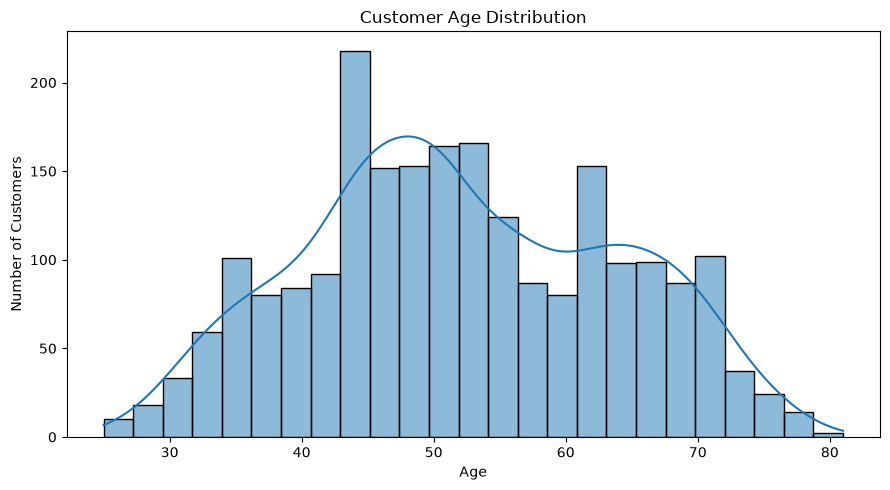

In [9]:
# 9. Age distribution
plt.figure(figsize=(9,5))
sns.histplot(data["Age"], bins=25, kde=True)
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


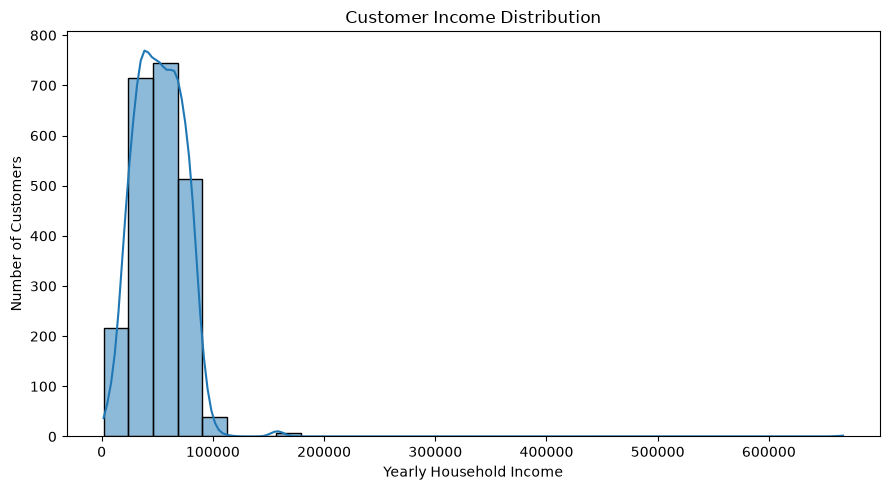

In [10]:
# 10. Income distribution
plt.figure(figsize=(9,5))
sns.histplot(data["Income"], bins=30, kde=True)
plt.title("Customer Income Distribution")
plt.xlabel("Yearly Household Income")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


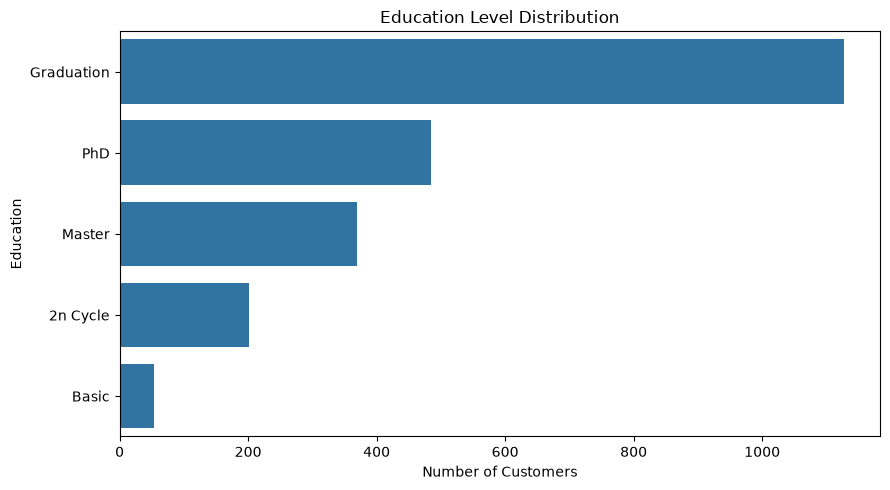

In [11]:
# 11. Education distribution
plt.figure(figsize=(9,5))
order = data["Education"].value_counts().index
sns.countplot(data=data, y="Education", order=order)
plt.title("Education Level Distribution")
plt.xlabel("Number of Customers")
plt.ylabel("Education")
plt.tight_layout()
plt.show()


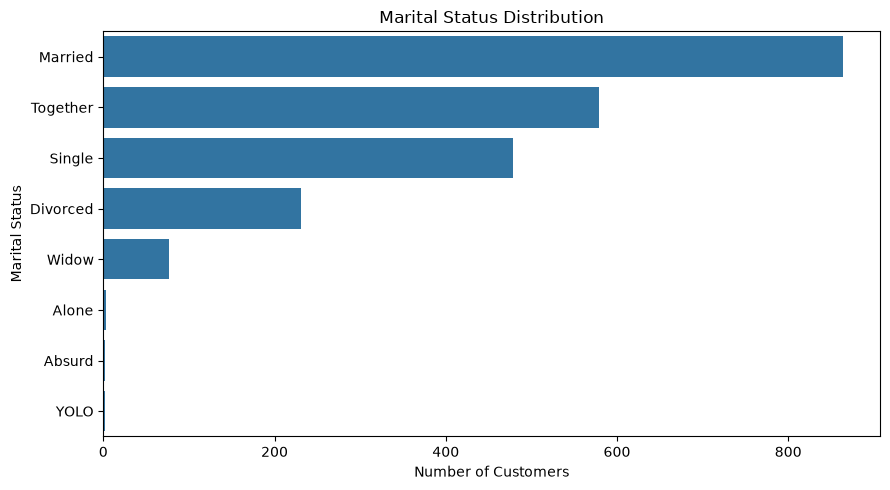

In [12]:
# 12. Marital status distribution
plt.figure(figsize=(9,5))
order = data["Marital_Status"].value_counts().index
sns.countplot(data=data, y="Marital_Status", order=order)
plt.title("Marital Status Distribution")
plt.xlabel("Number of Customers")
plt.ylabel("Marital Status")
plt.tight_layout()
plt.show()


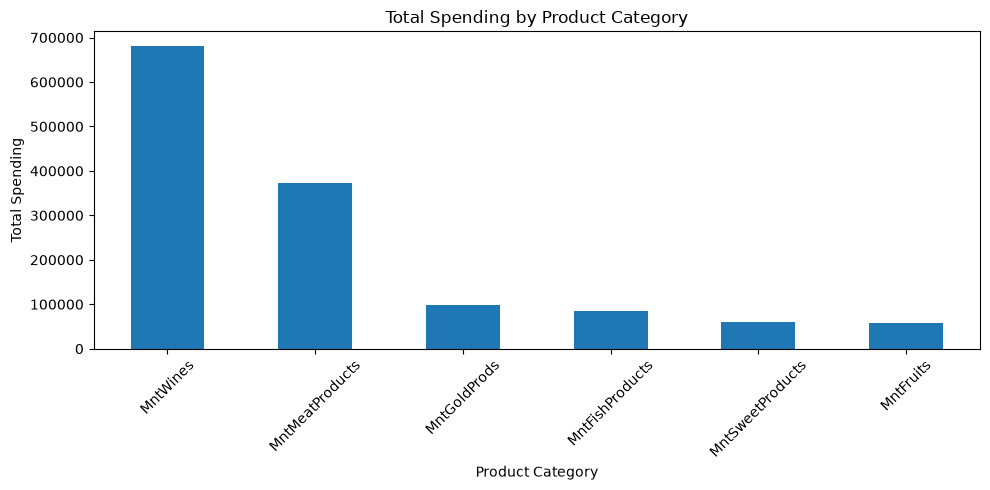

,Total_Spending
MntWines,680038
MntMeatProducts,373393
MntGoldProds,98358
MntFishProducts,83939
MntSweetProducts,60553
MntFruits,58767


In [13]:
# 13. Spending by product category
spending = data[product_cols].sum().sort_values(ascending=False)

plt.figure(figsize=(10,5))
spending.plot(kind="bar")
plt.title("Total Spending by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(spending.to_frame("Total_Spending"))


## 5. Feature relationships and correlations

The next section examines correlations and visual relationships between income, spending, purchases, web visits, household size and campaign response.


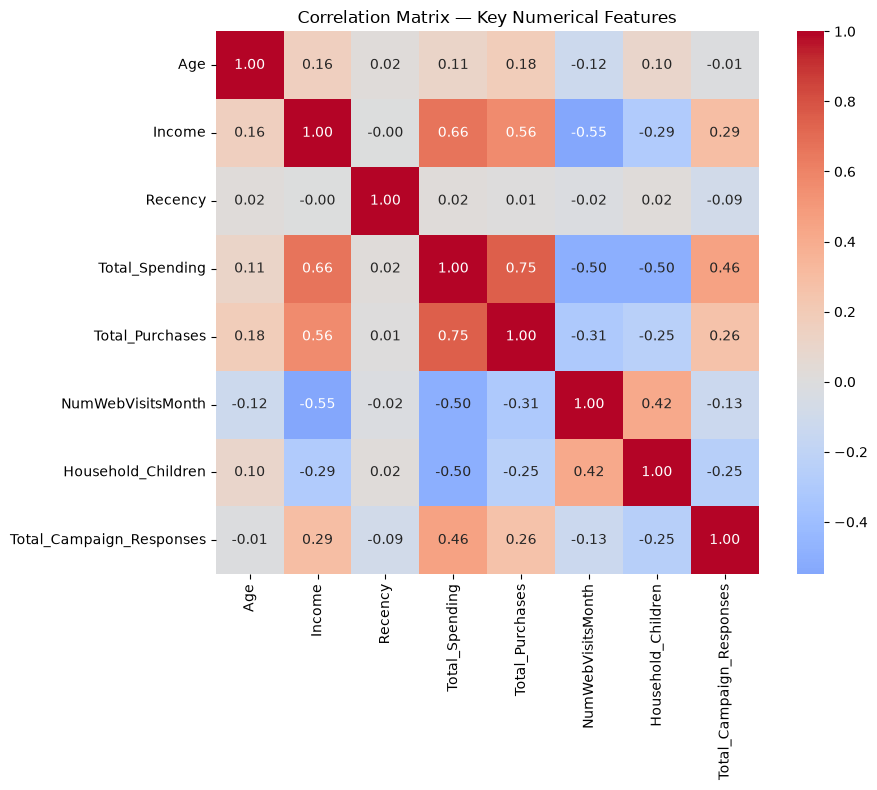

In [14]:
# 14. Correlation heatmap
corr_cols = [
    "Age", "Income", "Recency", "Total_Spending",
    "Total_Purchases", "NumWebVisitsMonth",
    "Household_Children", "Total_Campaign_Responses"
]

corr = data[corr_cols].corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Matrix — Key Numerical Features")
plt.tight_layout()
plt.show()


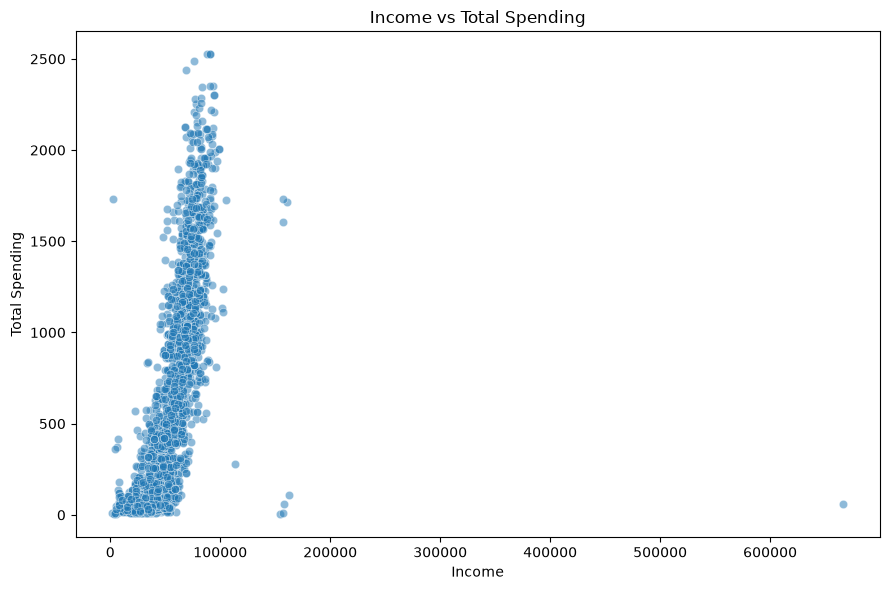

Pearson correlation: 0.665


In [15]:
# 15. Income vs total spending
plt.figure(figsize=(9,6))
sns.scatterplot(data=data, x="Income", y="Total_Spending", alpha=0.5)
plt.title("Income vs Total Spending")
plt.xlabel("Income")
plt.ylabel("Total Spending")
plt.tight_layout()
plt.show()

print("Pearson correlation:", round(data["Income"].corr(data["Total_Spending"]), 3))


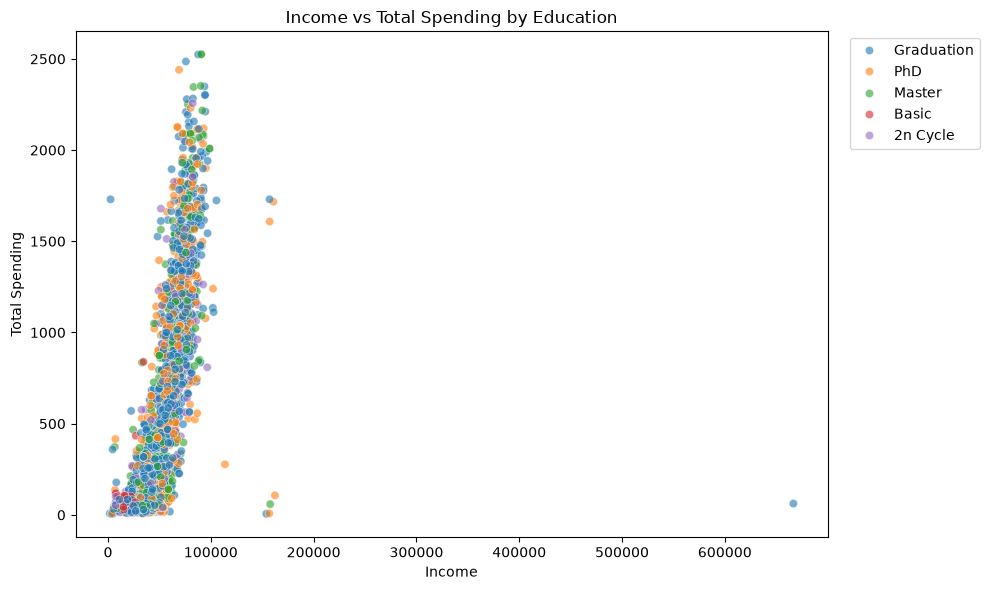

In [16]:
# 16. Income vs spending by education
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=data, x="Income", y="Total_Spending",
    hue="Education", alpha=0.6
)
plt.title("Income vs Total Spending by Education")
plt.xlabel("Income")
plt.ylabel("Total Spending")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


,mean,median,count
Education,,,
PhD,669.975258,493.0,485
Graduation,619.898846,414.0,1127
Master,611.781081,387.5,370
2n Cycle,501.034826,205.0,201
Basic,81.796296,57.0,54


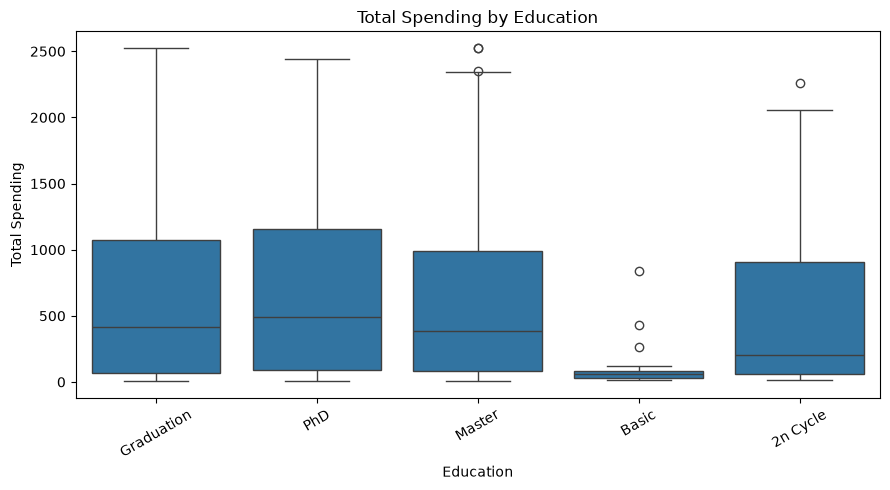

In [17]:
# 17. Spending by education
education_spending = (
    data.groupby("Education")["Total_Spending"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

display(education_spending)

plt.figure(figsize=(9,5))
sns.boxplot(data=data, x="Education", y="Total_Spending")
plt.title("Total Spending by Education")
plt.xlabel("Education")
plt.ylabel("Total Spending")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


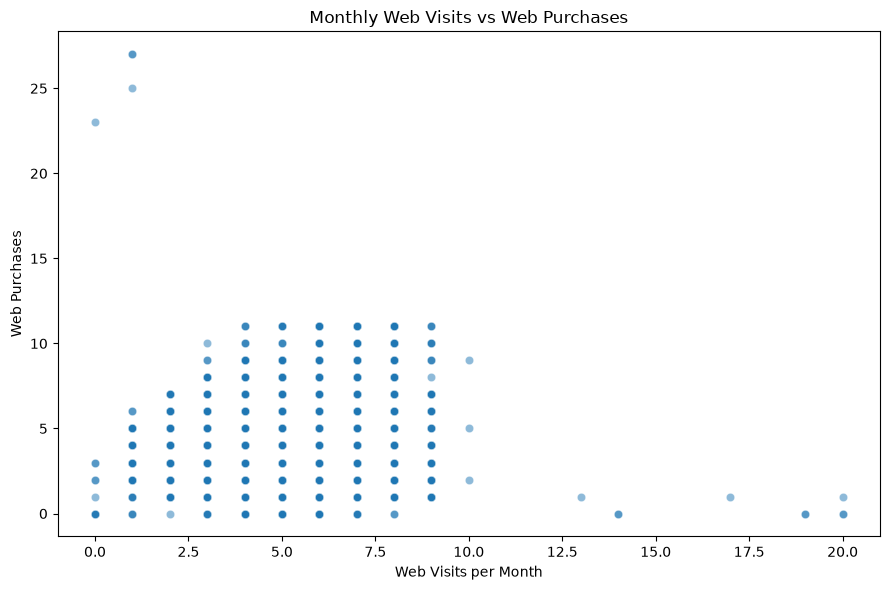

In [18]:
# 18. Web visits vs web purchases
plt.figure(figsize=(9,6))
sns.scatterplot(
    data=data, x="NumWebVisitsMonth",
    y="NumWebPurchases", alpha=0.5
)
plt.title("Monthly Web Visits vs Web Purchases")
plt.xlabel("Web Visits per Month")
plt.ylabel("Web Purchases")
plt.tight_layout()
plt.show()


## 6. Questions and data-driven findings

EDA is more useful when it answers concrete questions. The following cells calculate the answers from the actual dataset at runtime.


In [19]:
# 19. Question: Which education group has the highest average spending?
display(education_spending)

highest_group = education_spending["mean"].idxmax()
print("Highest average-spending education group:", highest_group)
print("Average spending:", round(education_spending.loc[highest_group, "mean"], 2))


,mean,median,count
Education,,,
PhD,669.975258,493.0,485
Graduation,619.898846,414.0,1127
Master,611.781081,387.5,370
2n Cycle,501.034826,205.0,201
Basic,81.796296,57.0,54


Highest average-spending education group: PhD
Average spending: 669.98


In [20]:
# 20. Question: Which product category contributes the most spending?
product_share = (spending / spending.sum() * 100).sort_values(ascending=False)
display(product_share.to_frame("Percentage_of_Total_Spending"))

print("Largest spending category:", spending.idxmax())


,Percentage_of_Total_Spending
MntWines,50.185528
MntMeatProducts,27.555703
MntGoldProds,7.258636
MntFishProducts,6.194541
MntSweetProducts,4.468698
MntFruits,4.336894


Largest spending category: MntWines


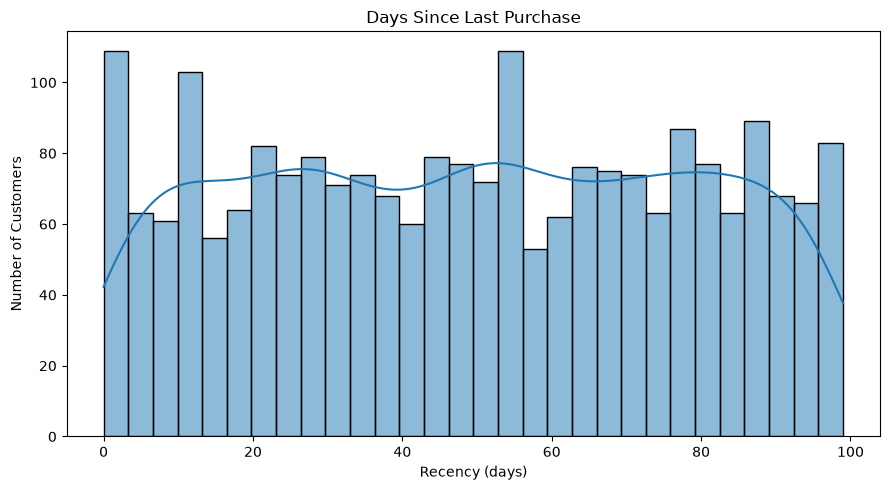

Median recency: 49.0 days


In [21]:
# 21. Question: How active are customers in recent purchasing?
plt.figure(figsize=(9,5))
sns.histplot(data["Recency"], bins=30, kde=True)
plt.title("Days Since Last Purchase")
plt.xlabel("Recency (days)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

print("Median recency:", data["Recency"].median(), "days")


In [22]:
# 22. Question: How do campaign responders differ?
response_summary = data.groupby("Response").agg(
    Customers=("ID", "count"),
    Average_Income=("Income", "mean"),
    Average_Spending=("Total_Spending", "mean"),
    Average_Purchases=("Total_Purchases", "mean"),
    Average_Recency=("Recency", "mean")
)

response_summary["Response_Label"] = response_summary.index.map({
    0: "Did not respond",
    1: "Responded"
})

display(response_summary)

response_rate = data["Response"].mean() * 100
print(f"Campaign response rate: {response_rate:.2f}%")


,Customers,Average_Income,Average_Spending,Average_Purchases,Average_Recency,Response_Label
Response,,,,,,
0,1903,50831.060168,538.759327,14.373095,51.512874,Did not respond
1,334,60183.244012,987.392216,17.706587,35.383234,Responded


Campaign response rate: 14.93%


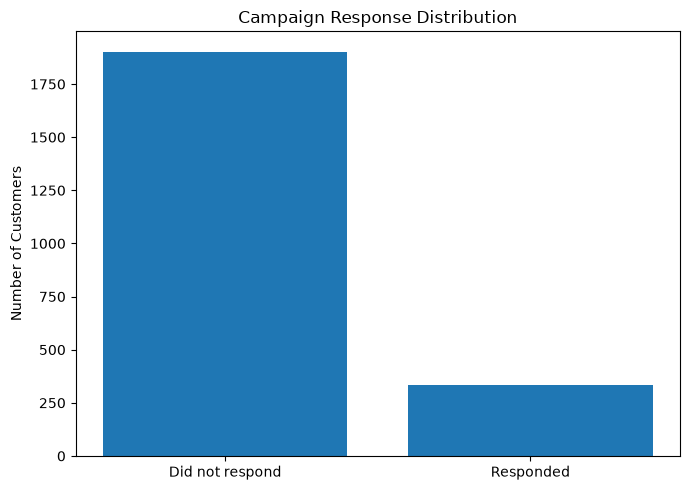

In [23]:
# 23. Campaign response visualization
counts = data["Response"].value_counts().sort_index()

plt.figure(figsize=(7,5))
plt.bar(
    ["Did not respond", "Responded"],
    [counts.get(0, 0), counts.get(1, 0)]
)
plt.title("Campaign Response Distribution")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


## 7. Outlier analysis

Outliers are inspected rather than automatically deleted. A high-income or high-spending customer may be a legitimate observation, so the EDA should distinguish unusual values from actual data errors.


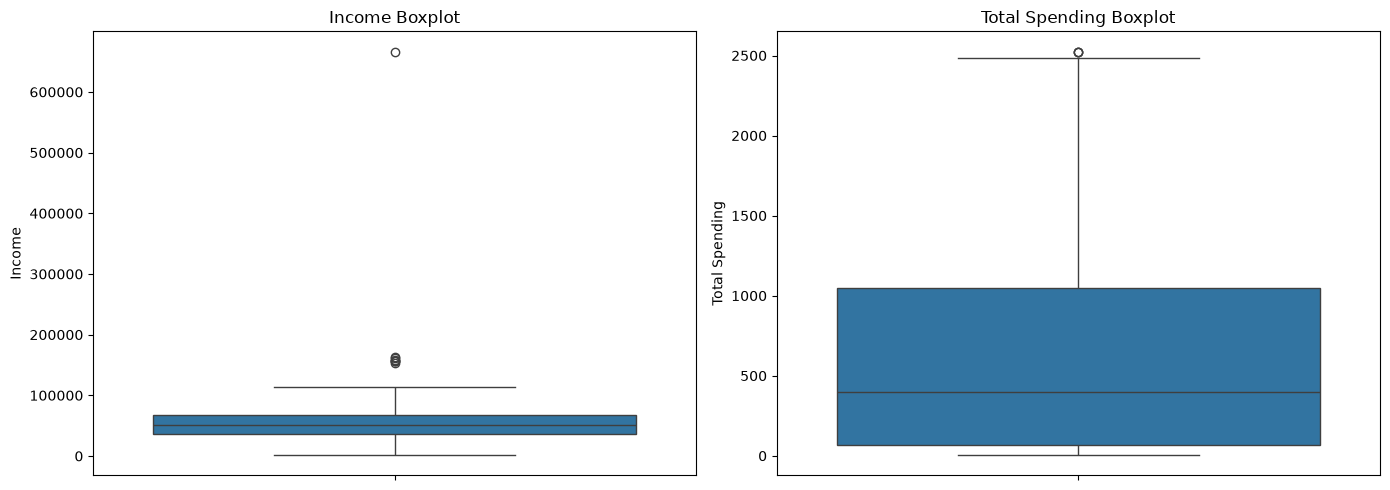

In [24]:
# 24. Outlier visualization
fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.boxplot(y=data["Income"], ax=axes[0])
axes[0].set_title("Income Boxplot")
axes[0].set_ylabel("Income")

sns.boxplot(y=data["Total_Spending"], ax=axes[1])
axes[1].set_title("Total Spending Boxplot")
axes[1].set_ylabel("Total Spending")

plt.tight_layout()
plt.show()


In [25]:
# 25. IQR-based outlier counts
def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((series < lower) | (series > upper)).sum()
    return count, lower, upper

for column in ["Income", "Total_Spending"]:
    count, lower, upper = iqr_outliers(data[column])
    print(f"{column}: {count} IQR-based outliers")
    print(f"Lower bound: {lower:.2f} | Upper bound: {upper:.2f}")


Income: 8 IQR-based outliers
Lower bound: -13614.00 | Upper bound: 117418.00
Total_Spending: 3 IQR-based outliers
Lower bound: -1395.00 | Upper bound: 2509.00


## 8. Final EDA summary

The following cell prints a concise summary using only values calculated from the dataset.


In [26]:
# 26. Automatically generated summary
income_spending_corr = data["Income"].corr(data["Total_Spending"])
top_product = spending.idxmax()
response_rate = data["Response"].mean() * 100
responder_spending = data.loc[data["Response"] == 1, "Total_Spending"].mean()
non_responder_spending = data.loc[data["Response"] == 0, "Total_Spending"].mean()

print("KEY FINDINGS")
print("=" * 60)
print(f"Prepared dataset: {len(data):,} customers.")
print(f"Median income: {data['Income'].median():,.2f}")
print(f"Median total spending: {data['Total_Spending'].median():,.2f}")
print(f"Median recency: {data['Recency'].median():.1f} days")
print(f"Highest average-spending education group: {highest_group}")
print(f"Largest product spending category: {top_product}")
print(f"Income vs total-spending correlation: {income_spending_corr:.3f}")
print(f"Campaign response rate: {response_rate:.2f}%")
print(f"Average spending — responders: {responder_spending:,.2f}")
print(f"Average spending — non-responders: {non_responder_spending:,.2f}")


KEY FINDINGS
Prepared dataset: 2,237 customers.
Median income: 51,381.50
Median total spending: 396.00
Median recency: 49.0 days
Highest average-spending education group: PhD
Largest product spending category: MntWines
Income vs total-spending correlation: 0.665
Campaign response rate: 14.93%
Average spending — responders: 987.39
Average spending — non-responders: 538.76


## 9. Conclusion

This project demonstrates a complete EDA workflow: data loading, structural inspection, missing-value and duplicate checks, data preparation, feature engineering, statistical summaries, distributions, correlations, relationship analysis, outlier inspection and data-driven conclusions.

**Important:** All numerical findings are generated from the dataset when the notebook is executed. No results should be manually fabricated.


In [27]:
# 27. Save project outputs
output_dir = Path("eda_results")
output_dir.mkdir(exist_ok=True)

data.to_csv(output_dir / "cleaned_customer_personality.csv", index=False)

summary = pd.DataFrame({
    "Metric": [
        "Rows after cleaning",
        "Columns after feature engineering",
        "Median Income",
        "Median Total Spending",
        "Median Recency",
        "Campaign Response Rate (%)",
        "Income vs Total Spending Correlation"
    ],
    "Value": [
        len(data),
        data.shape[1],
        data["Income"].median(),
        data["Total_Spending"].median(),
        data["Recency"].median(),
        response_rate,
        income_spending_corr
    ]
})

summary.to_csv(output_dir / "eda_summary.csv", index=False)

print("Outputs saved in:", output_dir.resolve())


Outputs saved in: C:\Users\thota\Downloads\eda_results
